You need to run each pip install in a separate block for it to work (not sure why)

In [1]:
#pip install pyblp
#pip install pandas
#pip install pyRVtest
#pip install matplotlib
#pip install Jinja2

In [2]:
import pyblp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyRVtest
from IPython.display import display

import io
import re
from contextlib import redirect_stdout


pyblp.options.digits = 5
pyblp.options.verbose = False
pyblp.__version__

'1.1.2'

In [3]:
#choose the dataset you want
product_data = pd.read_csv("nonLev_funds_product_month_level_v2_patched.csv")

# need to create unique market id
product_data["market_ids"] = product_data.groupby(["month_t"]).ngroup()+1

display(product_data[["month_t", "market_ids"]].drop_duplicates().sort_values("market_ids").head())

# create some variable needed for estimation
product_data["log_product_fund_age"] = np.log(product_data["product_fund_age"])
product_data["product_tracking_err"] = abs(product_data["product_tracking_err"])

# additional filters
product_data = product_data.dropna(subset=['Conduct_IV_csent_index_resid'])

# cluster_id for cluster SE
product_data['clustering_ids'] = product_data.market_ids

display(product_data["market_ids"].describe())


,month_t,market_ids
34900,1994.000000,1
34901,1994.083333,2
34902,1994.166667,3
34903,1994.250000,4
34904,1994.333333,5


count    546665.000000
mean        266.649211
std          79.852621
min           1.000000
25%         214.000000
50%         279.000000
75%         333.000000
max         382.000000
Name: market_ids, dtype: float64

In [4]:
# need to rename to prices and shares  and IV for using built in package below
product_data = product_data.rename(columns={
    'product_exp_ratio': 'prices',
    'market_share': 'shares_old',
    'BLP_IV_hausman_exp_ratio': 'demand_instruments0',
    #'IV2_exp_ratio_vw': 'demand_instruments1', # This is not needed for logit which only requires one IV for the price
    'firm_f': 'firm_ids',
    'product_j': 'product_ids',
})

# need to recompute market share to make sure they sum up to 1 (PyBLP needs they sum up to less than 1!)
product_data["shares"] = (
    product_data["product_mtna"] / product_data["market_share_m_denom_alt1"]
)

# filters for outside option
product_data = product_data.loc[product_data['shares'] >= 0.0001]
product_data = product_data.loc[product_data['month_t'] >=2010]
product_data = product_data.loc[product_data['month_t'] <=(2024+8/12)]
product_data = product_data[product_data['prefer'].isin([1,2,3,4,5])]
product_data = product_data.loc[product_data['prices'] > 0] ### Prices equal to zero inside outside option


# add together the residualized negative index returns
product_data["rotator"] = (
    product_data["Conduct_IV_neg_vw_ind_resid_1m"] + product_data["Conduct_IV_neg_vw_ind_resid_2to5m"] + product_data["Conduct_IV_neg_vw_ind_resid_6to12m"]
)

display(product_data["prices"].describe())
display(product_data["shares_old"].describe())
display(product_data["shares"].describe())
display(product_data["product_mtna"].describe())
display(product_data["firm_ids"].describe())
display(product_data["product_ids"].describe())

display(product_data.info())
display(product_data.head(10))

count    108300.000000
mean          0.285486
std           0.263334
min           0.010000
25%           0.080000
50%           0.200000
75%           0.440000
max           2.850000
Name: prices, dtype: float64

count    108300.000000
mean          0.001391
std           0.003518
min           0.000102
25%           0.000182
50%           0.000386
75%           0.001053
max           0.051506
Name: shares_old, dtype: float64

count    108300.000000
mean          0.001347
std           0.003407
min           0.000100
25%           0.000176
50%           0.000374
75%           0.001019
max           0.049652
Name: shares, dtype: float64

count    108300.000000
mean       9201.351229
std       28069.819713
min         175.500000
25%        1056.075000
50%        2292.950000
75%        6416.150000
max      700879.400000
Name: product_mtna, dtype: float64

count       108300
unique          90
top       Vanguard
freq         26697
Name: firm_ids, dtype: object

count    108300.000000
mean      38579.719381
std       19792.226957
min        3620.000000
25%       25138.000000
50%       35773.000000
75%       50970.000000
max      102153.000000
Name: product_ids, dtype: float64

<class 'pandas.core.frame.DataFrame'>
Index: 108300 entries, 500 to 579513
Columns: 114 entries, market_m_index to rotator
dtypes: float64(87), int64(17), object(10)
memory usage: 95.0+ MB


None

,market_m_index,month_t,product_ids,quarter,firm_f_old,market_m_cluster,market_m_index_mret,product_fund_name,product_mnav,product_mret,...,csent_index,csent_index_resid,csent_index_resid1,chg_VIX,chg_VIX_resid,market_ids,log_product_fund_age,clustering_ids,shares,rotator
500,ACDAPR,2015.500000,61338,2015.50,BZW,125,-0.011210,iShares Trust: iShares Core MSCI Pacific ETF,51.18,-0.002534,...,93.1,93.083587,93.264049,-6.11,-6.162540,259,0.000000,259,0.000124,0.071163
501,ACDAPR,2015.583333,61338,2015.50,BZW,125,-0.071408,iShares Trust: iShares Core MSCI Pacific ETF,47.37,-0.074443,...,91.9,91.777561,89.749443,16.31,15.945612,260,0.080043,260,0.000137,0.118427
502,ACDAPR,2015.666667,61338,2015.50,BZW,125,-0.047834,iShares Trust: iShares Core MSCI Pacific ETF,44.79,-0.054465,...,87.2,87.094286,87.565339,-3.93,-4.164930,261,0.154151,261,0.000133,0.100883
503,ACDAPR,2015.750000,61338,2015.75,BZW,125,0.089557,iShares Trust: iShares Core MSCI Pacific ETF,48.70,0.087296,...,90.0,90.118353,90.206134,-9.43,-8.868116,262,0.223144,262,0.000135,0.067819
504,ACDAPR,2015.833333,61338,2015.75,BZW,125,-0.010846,iShares Trust: iShares Core MSCI Pacific ETF,48.28,-0.008624,...,91.3,91.286902,91.285323,1.06,0.992112,263,0.287682,263,0.000133,0.051163
505,ACDAPR,2015.916667,61338,2015.75,BZW,125,0.006050,iShares Trust: iShares Core MSCI Pacific ETF,48.11,0.009794,...,92.6,92.609845,92.532852,2.08,2.118012,264,0.348307,264,0.000140,0.032574
506,ACDAPR,2016.000000,61338,2016.00,BZW,125,-0.080133,iShares Trust: iShares Core MSCI Pacific ETF,44.14,-0.082519,...,92.0,91.818823,91.784019,1.99,1.437632,265,0.405465,265,0.000134,0.012219
507,ACDAPR,2016.083333,61338,2016.00,BZW,125,-0.020239,iShares Trust: iShares Core MSCI Pacific ETF,43.41,-0.016538,...,91.7,91.654948,91.648421,0.35,0.210477,266,0.459532,266,0.000132,0.051827
508,ACDAPR,2016.166667,61338,2016.00,BZW,125,0.079671,iShares Trust: iShares Core MSCI Pacific ETF,46.47,0.070491,...,91.0,91.110384,91.006656,-6.60,-6.016799,267,0.510826,267,0.000127,0.040647
509,ACDAPR,2016.250000,61338,2016.25,BZW,125,0.032175,iShares Trust: iShares Core MSCI Pacific ETF,48.19,0.037013,...,89.0,89.037657,89.051985,1.75,1.990254,268,0.559616,268,0.000140,0.025154


In [5]:
# Compare share old (from CSV) and new (computed by me in python)
exact_match = (product_data["shares"] == product_data["shares_old"]).all()
close_match = np.allclose(product_data["shares"], product_data["shares_old"], rtol=1e-8, atol=1e-12)
abs_diff = (product_data["shares"] - product_data["shares_old"]).abs().max()

print("Exact equality:          ", exact_match)
print("All close (float-safe):  ", close_match)
print("Max absolute difference: ", abs_diff)

# Ad-hoc solution to make sure PyBLP run
#product_data["shares"] *= 0.5


Exact equality:           False
All close (float-safe):   False
Max absolute difference:  0.0022381709229742294


In [6]:
# Prepare Logit with Demand Rotator
logit_formulation = pyblp.Formulation('prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')
logit_formulation


prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)]

In [7]:
# Show logit problem
logit_problem = pyblp.Problem(logit_formulation, product_data)
logit_problem

Dimensions:
 T     N      F    K1    MD    ED 
---  ------  ---  ----  ----  ----
166  108300  90    4     4     2  

Formulations:
     Column Indices:          0              1                     2                     3          
--------------------------  ------  --------------------  --------------------  --------------------
X1: Linear Characteristics  prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age

In [8]:
# Solve logit
logit_results = logit_problem.solve(se_type='clustered')
logit_results

Problem Results Summary:
GMM    Objective   Clipped  Weighting Matrix  Covariance Matrix
Step     Value     Shares   Condition Number  Condition Number 
----  -----------  -------  ----------------  -----------------
 2    +1.0298E-24     0       +5.0371E+01        +2.6855E+04   

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs Adjusted for 166 Clusters in Parentheses):
   prices      product_tracking_err  product_past_1yr_ret  log_product_fund_age
-------------  --------------------  --------------------  --------------------
 -5.6060E+00       -4.5097E-01           +4.1319E-01           +5.7255E-01     
(+1.3102E+00)     (+6.5729E-02)         (+3.4143E-02)         (+1.1237E-02)    

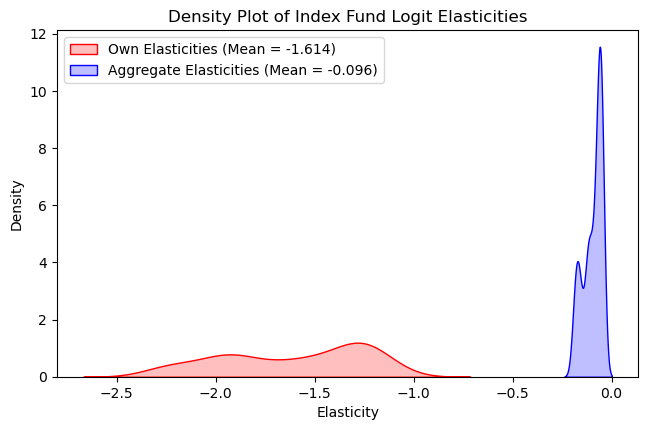

In [9]:
# compute elasticities, diversion ratio
logit_elasticities = logit_results.compute_elasticities()
logit_diversions = logit_results.compute_diversion_ratios()
logit_means = logit_results.extract_diagonal_means(logit_elasticities)
logit_aggregates = logit_results.compute_aggregate_elasticities(factor=0.1)

mean_own = logit_means.flatten().mean()
mean_agg = logit_aggregates.flatten().mean()

import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(logit_means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(logit_aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Index Fund Logit Elasticities")

# Save and show
plt.savefig("./logit_lasticities_density_Index.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [10]:
# Elasticities of the other variables
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='log_product_fund_age')).flatten().mean())

-0.015486614941538818
0.04234020146851647
1.2466597874915675


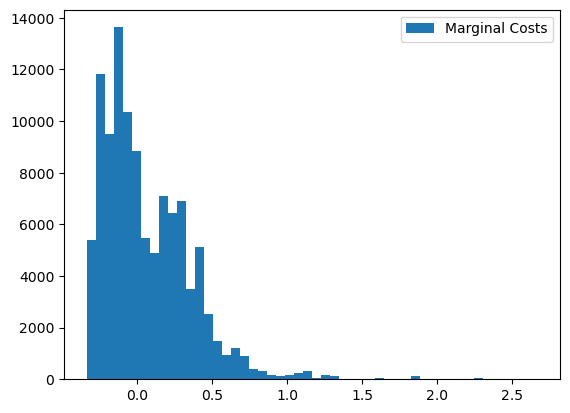

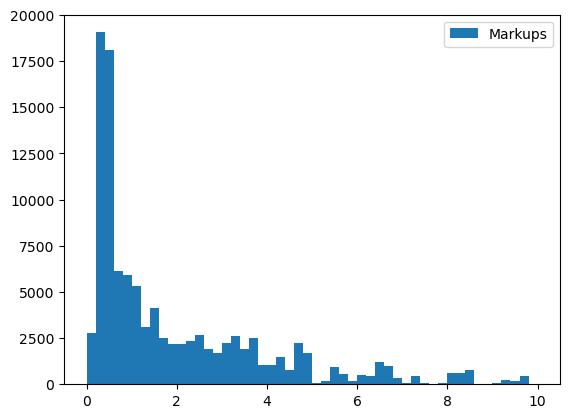

array([[-0.10290905],
       [-0.10247037],
       [-0.10279147],
       ...,
       [ 0.4715305 ],
       [ 0.47148664],
       [ 0.47148437]], shape=(108300, 1))

array([[1.93553681],
       [1.93154886],
       [1.93446791],
       ...,
       [0.27456847],
       [0.27463594],
       [0.27463943]], shape=(108300, 1))

count    108300.000000
mean          0.061403
std           0.293474
min          -0.338210
25%          -0.156637
50%          -0.017060
75%           0.242653
max           2.671594
dtype: float64

count    108300.000000
mean          2.187633
std           2.928885
min           0.062598
25%           0.450701
50%           1.084706
75%           3.094862
max          34.821027
dtype: float64

In [11]:
# compute costs and markups
costs = logit_results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./logit_marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

markups = logit_results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./logit_markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

display(costs)
display(markups)

display(pd.Series(costs.ravel()).describe())
display(pd.Series(markups.ravel()).describe())


In [12]:
# For BLP we need more instruments
product_data = product_data.rename(columns={
    # This is too correlated with BLP_IV_hausman_exp_ratio (renamed as demand_instruments1 above for logit estimation)
    #'BLP_IV_hausman_op_cost': 'demand_instruments1',
    # This one seems to work since it has some nice independent variation
    'BLP_IV_newproduct_1': 'demand_instruments1'
    # This 
    #'BLP_IV_rival_funds4': 'demand_instruments2'
})

# Prepare BLP 
X1_formulation = pyblp.Formulation('0 + prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

(prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)],
 prices)

In [13]:
mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

Configured to construct nodes and weights with Monte Carlo simulation with options {seed: 623543}.

In [14]:
mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

Dimensions:
 T     N      F     I      K1    K2    MD    ED 
---  ------  ---  ------  ----  ----  ----  ----
166  108300  90   498000   4     1     5     2  

Formulations:
       Column Indices:           0              1                     2                     3          
-----------------------------  ------  --------------------  --------------------  --------------------
 X1: Linear Characteristics    prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
X2: Nonlinear Characteristics  prices                                                                  

In [15]:
bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

Configured to optimize using the BFGS algorithm implemented in SciPy with analytic gradients and options {gtol: +1.0000E-07}.

In [16]:
# Solve BLP
results = mc_problem.solve(np.ones((1,1)), optimization=bfgs, se_type='clustered')
results

Problem Results Summary:
GMM    Objective    Gradient                 Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm        Hessian    Shares   Condition Number  Condition Number 
----  -----------  -----------  -----------  -------  ----------------  -----------------
 2    +5.7558E-01  +1.1312E-09  +1.6943E+00     0       +5.1317E+04        +1.5184E+18   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 00:20:14       Yes          4             8          4399         14494   

Nonlinear Coefficient Estimates (Robust SEs Adjusted for 166 Clusters in Parentheses):
Sigma:     prices    
------  -------------
prices   +2.6632E-02 
        (+1.2625E-02)

Beta Estimates (Robust SEs Adjusted for 166 Clusters in Parentheses):
   prices      product_tracking_err  pro

In [17]:
# compute elasticities, diversion ratio, costs, and markups
elasticities = results.compute_elasticities()
diversions = results.compute_diversion_ratios()
costs = results.compute_costs()
markups = results.compute_markups(costs=costs)

In [18]:
means = results.extract_diagonal_means(elasticities)
aggregates = results.compute_aggregate_elasticities(factor=0.1)

In [19]:
# Elasticities of the other variables
print(results.extract_diagonal_means(results.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(results.extract_diagonal_means(results.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(results.extract_diagonal_means(results.compute_elasticities(name='log_product_fund_age')).flatten().mean())

-0.017351965293279068
0.04238202425010448
1.2634105345140878


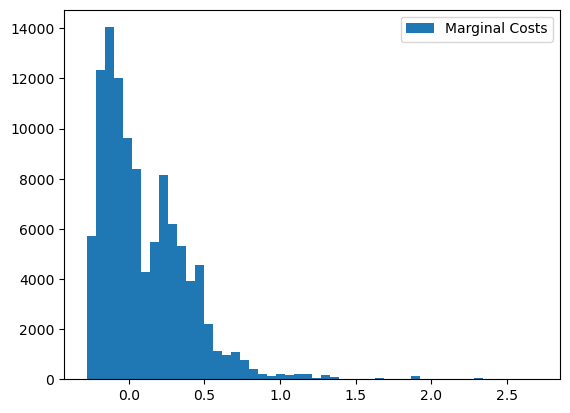

In [20]:
costs = results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

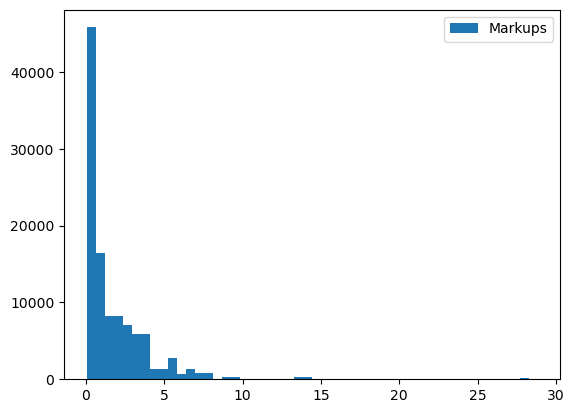

In [21]:
markups = results.compute_markups(costs=costs)
plt.hist(markups, bins=50);
plt.legend(["Markups"]);
plt.savefig("./markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

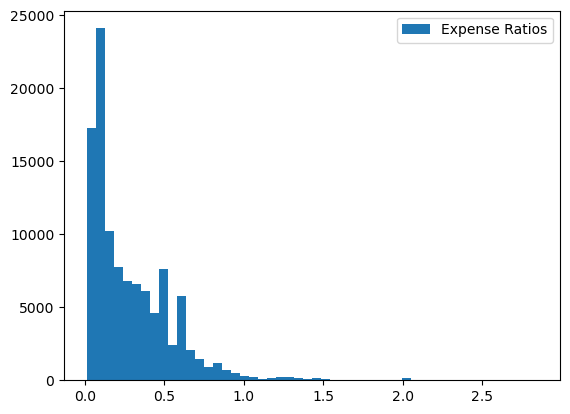

In [22]:
prices = product_data["prices"]
plt.hist(prices, bins=50);
plt.legend(["Expense Ratios"]);
plt.savefig("./expenseratio_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [23]:
# For BLP with more RCs, we need more instruments
product_data["log_BLP_IV_rival_log_fund_age4"] = np.log(product_data["BLP_IV_rival_log_fund_age4"])
product_data["log_BLP_IV_rival_tracking_err4"] = np.log(product_data["BLP_IV_rival_tracking_err4"])

product_data = product_data.rename(columns={
    'log_BLP_IV_rival_log_fund_age4': 'demand_instruments2'
})

product_data = product_data.rename(columns={
    'log_BLP_IV_rival_tracking_err4': 'demand_instruments3'
})

In [ ]:
# Prepare BLP with additional RCs V2
X1_formulation = pyblp.Formulation('0 + prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices + log_product_fund_age + product_past_1yr_ret')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

# Solve BLP
results_v3 = mc_problem.solve(np.identity(3), optimization=bfgs, se_type='clustered')
results_v3

In [ ]:
# compute elasticities, diversion ratio, costs, and markups for RC v3
elasticities = results_v3.compute_elasticities()
diversions = results_v3.compute_diversion_ratios()
costs = results_v3.compute_costs()
markups = results_v3.compute_markups(costs=costs)

means = results_v3.extract_diagonal_means(elasticities)
aggregates = results_v3.compute_aggregate_elasticities(factor=0.1)

mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()
mean_own

In [ ]:
# Elasticities of the other variables
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='log_product_fund_age')).flatten().mean())

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep your mean calculations
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Index Fund BLP Elasticities")

# Save and show
plt.savefig("./BLP_elasticities_density_Index.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# compute elasticities, diversion ratio
results_v3.compute_elasticities()

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = logit_results.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"logit_elasticities_nonlev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = results_v3.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"elasticities_nonlev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

In [ ]:
testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Save the level markup, level marginal cost, and lerner index data into the df
product_data['BLP_mu_pc'] = testing_results.markups[0]
product_data['BLP_mu_bt'] = testing_results.markups[1]
product_data['BLP_mu_bt_big3_025'] = testing_results.markups[2]
product_data['BLP_mu_bt_big3_050'] = testing_results.markups[3]
product_data['BLP_mu_bt_big3_055'] = testing_results.markups[4]
product_data['BLP_mu_bt_big3_060'] = testing_results.markups[5]
product_data['BLP_mu_bt_big3_065'] = testing_results.markups[6]
product_data['BLP_mu_bt_big3_070'] = testing_results.markups[7]
product_data['BLP_mu_bt_big3_075'] = testing_results.markups[8]
product_data['BLP_mu_cournot'] = testing_results.markups[9]
product_data['BLP_mu_monopoly'] = testing_results.markups[10]

product_data['BLP_mc_pc'] = testing_results.marginal_cost[0]
product_data['BLP_mc_bt'] = testing_results.marginal_cost[1]
product_data['BLP_mc_bt_big3_025'] = testing_results.marginal_cost[2]
product_data['BLP_mc_bt_big3_050'] = testing_results.marginal_cost[3]
product_data['BLP_mc_bt_big3_055'] = testing_results.marginal_cost[4]
product_data['BLP_mc_bt_big3_060'] = testing_results.marginal_cost[5]
product_data['BLP_mc_bt_big3_065'] = testing_results.marginal_cost[6]
product_data['BLP_mc_bt_big3_070'] = testing_results.marginal_cost[7]
product_data['BLP_mc_bt_big3_075'] = testing_results.marginal_cost[8]
product_data['BLP_mc_cournot'] = testing_results.marginal_cost[9]
product_data['BLP_mc_monopoly'] = testing_results.marginal_cost[10]

product_data['BLP_lerner_pc'] = product_data['BLP_mu_pc']/product_data['prices']
product_data['BLP_lerner_bt'] = product_data['BLP_mu_bt']/product_data['prices']
product_data['BLP_lerner_bt_big3_025'] = product_data['BLP_mu_bt_big3_025']/product_data['prices']
product_data['BLP_lerner_bt_big3_050'] = product_data['BLP_mu_bt_big3_050']/product_data['prices']
product_data['BLP_lerner_bt_big3_055'] = product_data['BLP_mu_bt_big3_055']/product_data['prices']
product_data['BLP_lerner_bt_big3_060'] = product_data['BLP_mu_bt_big3_060']/product_data['prices']
product_data['BLP_lerner_bt_big3_065'] = product_data['BLP_mu_bt_big3_065']/product_data['prices']
product_data['BLP_lerner_bt_big3_070'] = product_data['BLP_mu_bt_big3_070']/product_data['prices']
product_data['BLP_lerner_bt_big3_075'] = product_data['BLP_mu_bt_big3_075']/product_data['prices']
product_data['BLP_lerner_cournot'] = product_data['BLP_mu_cournot']/product_data['prices']
product_data['BLP_lerner_monopoly'] = product_data['BLP_mu_monopoly']/product_data['prices']

print(np.mean(product_data['BLP_lerner_pc']>1))
print(np.mean(product_data['BLP_lerner_bt']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_025']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_050']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_055']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_060']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_065']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_070']>1))
print(np.mean(product_data['BLP_lerner_bt_big3_075']>1))
print(np.mean(product_data['BLP_lerner_cournot']>1))
print(np.mean(product_data['BLP_lerner_monopoly']>1))

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[2].ravel(), label='Bertrand (0.25 Profit Weights: Big 3)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[3].ravel(), label='Bertrand (0.50 Profit Weights: Big 3)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[8].ravel(), label='Bertrand (0.75 Profit Weights: Big 3)', color='green', fill=True, alpha=0.25)

#plt.xlim(0, 2)
#plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

#plt.savefig("./Bertrand and Partial Collusion Combos.pdf", format="pdf", bbox_inches="tight")
#plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_025'], label='Bertrand (0.25 Profit Weights: Big 3)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_050'], label='Bertrand (0.50 Profit Weights: Big 3)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_big3_065'], label='Bertrand (0.65 Profit Weights: Big 3)', color='green', fill=True, alpha=0.25)

plt.xlim(-2, 10)
#plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Lerner Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-5, 40)
#plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Lerner Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_mc_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-2, 4)
plt.ylim(0, 3)
plt.xlabel('Marginal Costs implied by Conduct (percentage points per annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index MC Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[9].ravel(), label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[10].ravel(), label='Monopoly', color='green', fill=True, alpha=0.25)

#plt.xlim(0, 1)
#plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Index Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Save implied marginal costs
product_data.to_csv("nonlev_product_data_w_costs_Mar2025_matchEgan.csv", index=False)
#product_data.to_csv("nonlev_product_data_w_costs_Mar2025_matchEgan_BLP1RC.csv", index=False)

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )


# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2 + BLP_IV_rival_funds2:Conduct_IV_csent_index_resid + Conduct_IV_csent_index_resid')      

### These interactions support PC
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_bab_usa_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_fmax_resid
# This works: BLP_IV_rival_funds2*rotator
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 0 if {f, g} == {"BlackRock", "Vanguard"}
        else 0 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 0.25 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.25 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.25 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 0.5 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.5 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.5 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 0.55 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.55 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.55 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 0.60 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.60 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.60 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 0.65 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.65 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.65 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 0.70 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.70 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.70 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 0.75 if {f, g} == {"BlackRock", "Vanguard"}
        else 0.75 if {f, g} == {"BlackRock", "State Street Global Advisors"}
        else 0.75 if {f, g} == {"Vanguard", "State Street Global Advisors"}
        else 0
    )


# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.024)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Counterfactual
product_data_econ_scale=copy.deepcopy(product_data)

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (   
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      
    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

#costs_baseline = testing_results.marginal_cost[0] + (-0.024)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)

costs_baseline = testing_results.marginal_cost[0]  ### Force price = mc
prices_baseline = costs_baseline

print(costs_baseline.flatten().mean())
print(prices_baseline.flatten().mean())

shares_baseline = results_v3.compute_shares(
prices=prices_baseline
)

profits_baseline = results_v3.compute_profits(
prices=prices_baseline,
    costs=costs_baseline,
shares=shares_baseline
)

surplus_baseline = results_v3.compute_consumer_surpluses(
prices=prices_baseline
)

print(shares_baseline.flatten().mean())
print(profits_baseline.flatten().mean())
print(surplus_baseline.flatten().mean())


In [ ]:
# Save counterfactuals
product_data['cf_costs_baseline'] = costs_baseline.reshape(-1,1)
product_data['cf_prices_baseline'] = prices_baseline.reshape(-1,1)
product_data['cf_shares_baseline'] = shares_baseline.reshape(-1,1)

In [ ]:
costs_noscale = testing_results.marginal_cost[0] - (-0.024)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)
markups_noscale = testing_results.markups[0]

prices_noscale = costs_noscale ### Force price = mc

print(costs_noscale.flatten().mean())
print(markups_noscale.flatten().mean())
print(prices_noscale.flatten().mean())

shares_noscale = results_v3.compute_shares(
prices=prices_noscale
)

profits_noscale = results_v3.compute_profits(
prices=prices_noscale,
    costs=costs_noscale,
shares=shares_noscale
)

surplus_noscale = results_v3.compute_consumer_surpluses(
prices=prices_noscale
)

print(shares_noscale.flatten().mean())
print(profits_noscale.flatten().mean())
print(surplus_noscale.flatten().mean())


In [ ]:
# Save counterfactuals
product_data['cf_costs_noscale'] = costs_noscale.reshape(-1,1)
product_data['cf_prices_noscale'] = prices_noscale.reshape(-1,1)
product_data['cf_shares_noscale'] = shares_noscale.reshape(-1,1)

In [ ]:
# Save implied marginal costs
product_data.to_csv("nonlev_product_data_w_costs_Oct2026_counterfactuals.csv", index=False)
